# Relevancia: comparación reconstruida y revisión de exclusiones

Esta libreta lee predicciones **fuera del fold de entrenamiento (OOF)** ya guardadas para SVM, regresión logística y control por plataforma. No entrena modelos. Los 160 textos de la reconstrucción no son los 168 del experimento histórico. Se excluyeron los inciertos; la aprobación de etiquetas asistidas no fue una anotación ciega independiente.

La comparación usa las mismas filas y folds. El control aprende la clase mayoritaria por plataforma dentro de cada fold. La elección de SVM utilizó estos mismos resultados: no constituyen un test independiente de esa selección.


In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/voc").is_dir())
NB_ROOT = REPO / "reports/drafts/difusion"
if str(NB_ROOT) not in sys.path: sys.path.insert(0, str(NB_ROOT))
from apoyo_validacion import digest, export_bundle, show_texts
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})


In [2]:
from voc.paths import data_root
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, confusion_matrix
source=REPO/"docs/evidence/relevance-comparison-v1.json"
receipt=json.loads(source.read_text())
svm_path=data_root()/"relevance/model-v1/validation.csv"
lr_path=data_root()/"relevance/model-logreg-v1/validation.csv"
assert digest(svm_path)==receipt["svm_validation_sha256"]
assert digest(lr_path)==receipt["logreg_validation_sha256"]
svm=pd.read_csv(svm_path);lr=pd.read_csv(lr_path)
assert svm[["record_id","target","fold","platform"]].equals(lr[["record_id","target","fold","platform"]])
assert svm.record_id.is_unique and len(svm)==160
assert svm.platform_control.equals(lr.platform_control)
predictions={"SVM":svm.prediction,"Logística":lr.prediction,"Control plataforma":svm.platform_control}
metric_rows=[];matrices={};platform_rows=[]
for name,pred in predictions.items():
    precision,recall,f1,_=precision_recall_fscore_support(svm.target,pred,average="binary",zero_division=0)
    cm=confusion_matrix(svm.target,pred,labels=[0,1]);matrices[name]=cm
    metric_rows.append({"model":name,"accuracy":accuracy_score(svm.target,pred),"balanced_accuracy":balanced_accuracy_score(svm.target,pred),"precision_relevant":precision,"recall_relevant":recall,"f1_relevant":f1,"irrelevant_passed":int(cm[0,1]),"relevant_lost":int(cm[1,0])})
    for platform in sorted(svm.platform.unique()):
        mask=svm.platform.eq(platform);sub=confusion_matrix(svm.loc[mask,"target"],pred[mask],labels=[0,1])
        platform_rows.append({"model":name,"platform":platform,"irrelevant_support":int(sub[0].sum()),"relevant_support":int(sub[1].sum()),"irrelevant_passed":int(sub[0,1]),"relevant_lost":int(sub[1,0])})
metrics=pd.DataFrame(metric_rows);platform_metrics=pd.DataFrame(platform_rows)
for name,key in [("SVM","svm"),("Logística","logistic_regression"),("Control plataforma","platform_control")]:
    for metric in ["accuracy","balanced_accuracy","precision_relevant","recall_relevant","f1_relevant"]:
        assert np.isclose(metrics.set_index("model").loc[name,metric],receipt[key][metric])
display(metrics.round(4));display(platform_metrics)


,model,accuracy,balanced_accuracy,precision_relevant,recall_relevant,f1_relevant,irrelevant_passed,relevant_lost
0,SVM,0.9125,0.9089,0.9271,0.9271,0.9271,7,7
1,Logística,0.9250,0.9167,0.9200,0.9583,0.9388,8,4
2,Control plataforma,0.9312,0.9271,0.9381,0.9479,0.9430,6,5


,model,platform,irrelevant_support,relevant_support,irrelevant_passed,relevant_lost
0,SVM,x,6,91,6,6
1,SVM,youtube,58,5,1,1
2,Logística,x,6,91,6,4
3,Logística,youtube,58,5,2,0
4,Control plataforma,x,6,91,6,0
5,Control plataforma,youtube,58,5,0,5


## Qué errores intercambiamos al elegir el filtro

Filas = referencia revisada; columnas = predicción. Relevante es la clase positiva. Un falso positivo deja pasar ruido; un falso negativo retira información potencialmente útil. No podemos sumar esta matriz con la evaluación histórica de 168 textos ni con las exclusiones del experimento integrado.

SVM dejó pasar siete irrelevantes y perdió siete relevantes; logística dejó pasar ocho y perdió cuatro. La preferencia operativa por SVM evita un irrelevante adicional a costa de tres pérdidas relevantes adicionales. Ninguno supera al control en accuracy o balanced accuracy. Los soportes por plataforma deben acompañar esa elección.


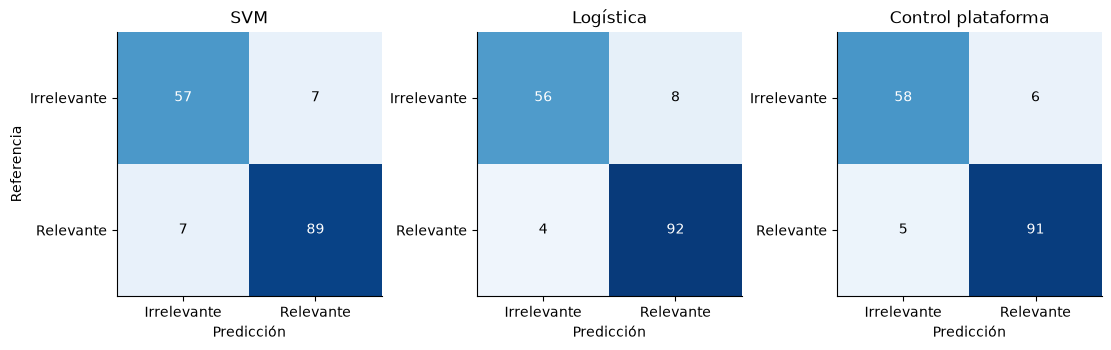

In [3]:
fig_relevance,axes=plt.subplots(1,3,figsize=(11,3.7),layout="constrained")
for ax,(name,cm) in zip(axes,matrices.items()):
    ax.imshow(cm,cmap="Blues",vmin=0,vmax=96)
    for i in range(2):
        for j in range(2):ax.text(j,i,str(cm[i,j]),ha="center",va="center",color="white" if cm[i,j]>48 else "black")
    ax.set(xticks=[0,1],yticks=[0,1],xticklabels=["Irrelevante","Relevante"],yticklabels=["Irrelevante","Relevante"],xlabel="Predicción",title=name)
axes[0].set_ylabel("Referencia")
plt.show()


## Revisión humana de las 13 exclusiones de julio–agosto

Es otra población y otra pregunta: ¿cuáles de los descartes de la muestra integrada fueron aceptados por el revisor? Se conservaron diez descartes como irrelevantes y tres se consideraron pérdidas relevantes. No se revisaron todos los retenidos, por lo que esta sección no calcula recall ni accuracy global. La revisión fue posterior a ver decisiones y observaciones asistidas.


human_label,irrelevant,relevant
platform,,
x,1,1
youtube,9,2


Autoría y alcance: journal/linear/WOR-228-producto-difusion/context/buffer.md


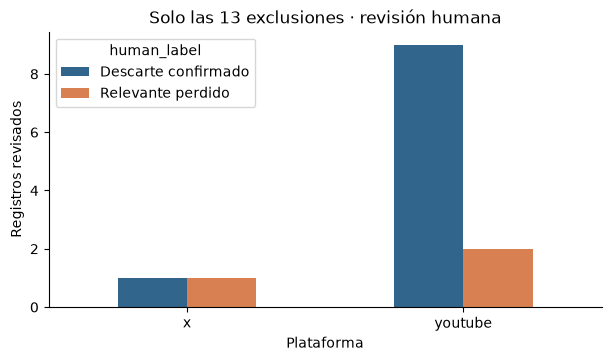

In [4]:
human_path=data_root()/"experiments/julaug-2026/human-review-v1/review.json"
human=json.loads(human_path.read_text());review_df=pd.DataFrame(human["rows"])
assert len(review_df)==13 and review_df.record_id.is_unique
assert review_df.human_label.value_counts().to_dict()=={"irrelevant":10,"relevant":3}
human_table=pd.crosstab(review_df.platform,review_df.human_label)
display(human_table)
print("Autoría y alcance:",human.get("source"))
fig_exclusions,ax=plt.subplots(figsize=(6,3.5),layout="constrained")
human_table.reindex(columns=["irrelevant","relevant"],fill_value=0).rename(columns={"irrelevant":"Descarte confirmado","relevant":"Relevante perdido"}).plot.bar(ax=ax,rot=0,color=["#31658B","#D88052"])
ax.set(ylabel="Registros revisados",xlabel="Plataforma",title="Solo las 13 exclusiones · revisión humana")
plt.show()


## Exportación

Exportamos los resultados de la libreta para elaborar el reporte.


In [5]:
exported=export_bundle(NB_ROOT/"evaluacion-filtro-relevancia.ipynb",
 {"relevancia-oof":fig_relevance,"relevancia-exclusiones-humanas":fig_exclusions},
 {"metricas-oof":metrics,"errores-por-plataforma":platform_metrics,"revision-exclusiones":review_df},
 {"alcance":{"oof_rows":160,"human_exclusions_reviewed":13,"independent_selection_test":False}},
 {name:{"path":str(p.relative_to(REPO)),"sha256":digest(p)} for name,p in {"comparison_receipt":source,"svm_oof":svm_path,"logistic_oof":lr_path,"human_exclusions":human_path}.items()},
 "Reconstructed relevance OOF evaluation and separate human review of integrated exclusions; no training")


Evidencia exportada: /workspace/vaults/sonar/code/repos/voc-difusion/reports/difusion/exports/evaluacion-filtro-relevancia/20261105T191417687054Z
